# Fund Detective — Investment Advisory Assignment

**Your role:** You are an investment advisor at a wealth management firm. Your firm has received daily total returns for three anonymous equity funds, **Fund A**, **Fund B**, and **Fund C**. Their managers have not disclosed their strategies or portfolios.

A client wants to understand what these funds actually invest in, which risks they take, and whether any of them deserves a place in an investment portfolio. Your job is to provide an evidence-based recommendation.

**Data:** Daily returns for 2015–2025, expressed in USD, and the S&P 500 proxy (SPY). The funds' real names will be revealed after your analysis.

**Deliverable:** Submit this notebook with all calculations, charts and answers, plus a concise recommendation for the client. Do not assume that a high historical return implies superior skill or future performance.

## 0. Data and market information

The client has supplied an anonymized daily-return file. Publicly available Fama–French factor and industry return series are provided below. Work with the data supplied, and state any limitations that could affect your recommendation.

In [1]:
%pip -q install pandas-datareader statsmodels matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pandas_datareader import data as web
from IPython.display import display
import pandas_datareader.famafrench as ff_module

In [3]:
data_url = 'https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Finance_Technology/Tema_5_APT/data/fund_detective_anonymous_daily_returns_2015_2025.csv'

In [4]:
# Download the monthly Fama–French and industry datasets.
# The original sources report returns in percent; convert to decimals.


ff_module._URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/'

def get_french_data(dataset):
    df = web.DataReader(
        dataset, 'famafrench',
        start='2015-01-01',
        end='2025-12-31'
    )[0].copy()

    df.columns = df.columns.str.strip()
    return df / 100

ff_us = get_french_data('F-F_Research_Data_Factors')
ff_europe = get_french_data('Europe_3_Factors')
industries_us = get_french_data('5_Industry_Portfolios')

print('US factors:', ff_us.columns.tolist())
print('European factors:', ff_europe.columns.tolist())
print('US industry portfolios:', industries_us.columns.tolist())

US factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
European factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
US industry portfolios: ['Cnsmr', 'Manuf', 'HiTec', 'Hlth', 'Other']


### 1. Fund Performance and Risk Analysis

Before making any investment decision, I would like to understand how the three funds have performed compared with the S&P 500.

Please prepare an analysis addressing the following questions:

1. What are the **annualized returns, annualized volatilities, maximum drawdowns, and Sharpe ratios** of the three funds and the S&P 500?
2. How would an initial investment of **$100** in each fund and the S&P 500 have evolved over the period?
3. How strongly are the funds' returns correlated with the S&P 500?
4. Which fund has delivered the highest return? Which has offered the best risk-adjusted performance?
5. Which fund has experienced the largest losses during market downturns?
6. Based on these results, which fund would you consider most attractive, and what additional information would you need before recommending it?

In [40]:
data = pd.read_csv(data_url,index_col= "Date",parse_dates = True)
df = data.copy()

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2766 entries, 2015-01-02 to 2025-12-31
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Fund A  2766 non-null   float64
 1   Fund B  2766 non-null   float64
 2   Fund C  2766 non-null   float64
 3   SPY     2766 non-null   float64
dtypes: float64(4)
memory usage: 108.0 KB


In [17]:
df

,Fund A,Fund B,Fund C,SPY
Date,,,,
2015-01-02,-0.001461,-0.001766,-0.009073,-0.000535
2015-01-05,-0.017125,-0.017955,-0.018598,-0.018059
2015-01-06,-0.011467,-0.010898,-0.009329,-0.009419
2015-01-07,0.015969,0.010563,0.001471,0.012461
2015-01-08,0.018980,0.016129,0.012342,0.017745
...,...,...,...,...
2025-12-24,0.002075,0.002874,-0.000214,0.003518
2025-12-26,0.000333,0.000716,0.001926,-0.000101
2025-12-29,-0.005249,-0.002863,-0.002698,-0.003564


In [34]:
df_means = df.mean() * 252
df_vol = df.std() * np.sqrt(252)
df_sharpe = df_means / df_vol

In [35]:
df_stats = pd.DataFrame({
    'Return': df_means,
    'Volatility': df_vol,
    'Sharpe Ratio': df_sharpe
})
display(df_stats)

,Return,Volatility,Sharpe Ratio
Fund A,0.194898,0.231069,0.843464
Fund B,0.113868,0.216485,0.525984
Fund C,0.084607,0.175622,0.481758
SPY,0.142086,0.177893,0.798717


REVISAR

In [65]:

# 1. Calculamos la riqueza acumulada (curva de capital)
wealth_index = (1 + df).cumprod()

# 2. Calculamos los picos históricos corriendo en el tiempo
previous_peaks = wealth_index.cummax()

# 3. Calculamos la serie de drawdowns
drawdowns = (wealth_index / previous_peaks) - 1

# 4. El Maximum Drawdown es el valor mínimo de esa serie
max_drawdowns = drawdowns.min()

df_stats['Max Drawdown'] = max_drawdowns
display(df_stats)

,Return,Volatility,Sharpe Ratio,Max Drawdown
Fund A,0.194898,0.231069,0.843464,-0.430848
Fund B,0.113868,0.216485,0.525984,-0.486607
Fund C,0.084607,0.175622,0.481758,-0.380427
SPY,0.142086,0.177893,0.798717,-0.337173


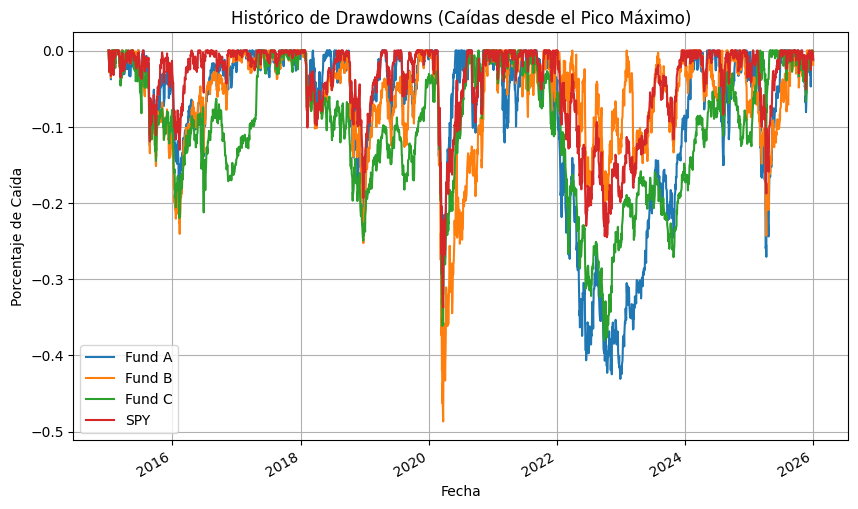

In [63]:
# Graficar la evolución de las caídas (Drawdowns) a lo largo del tiempo
drawdowns.plot(figsize=(10, 6))
plt.title("Histórico de Drawdowns (Caídas desde el Pico Máximo)")
plt.ylabel("Porcentaje de Caída")
plt.xlabel("Fecha")
plt.grid(True)
plt.show()

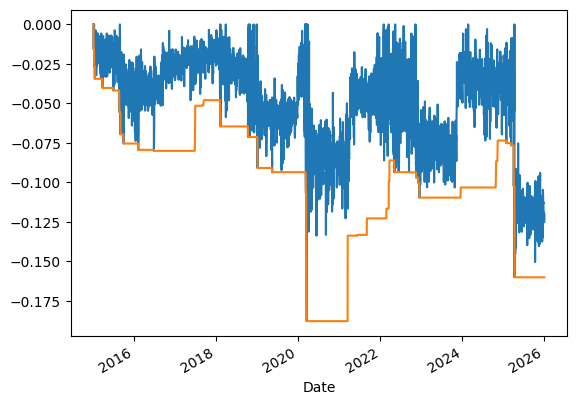

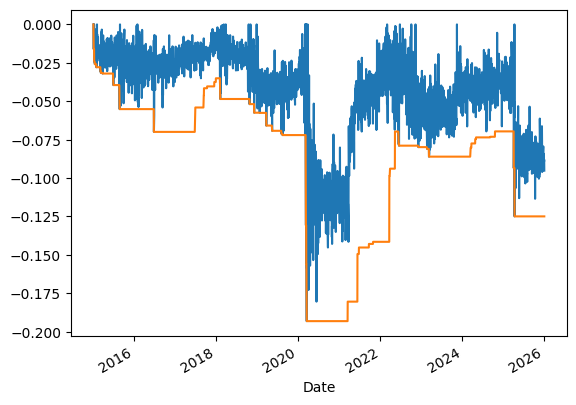

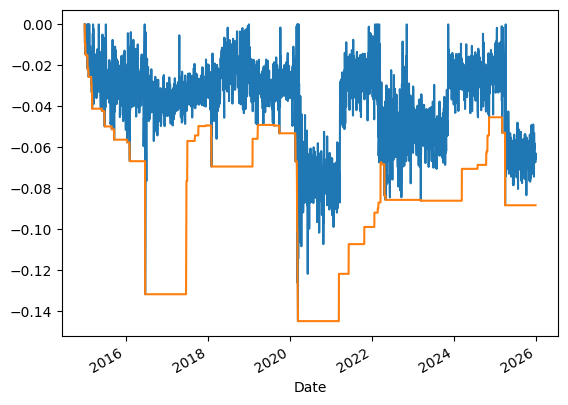

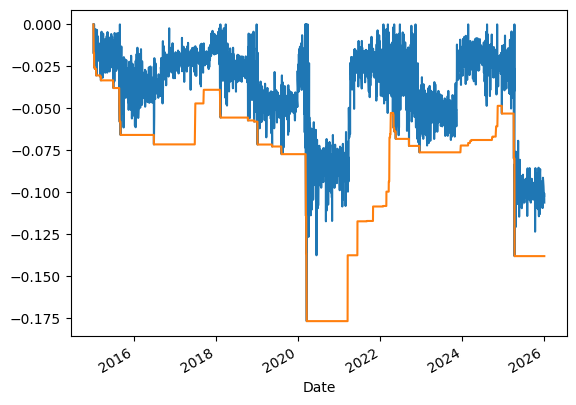

In [42]:
window = 252

prices = np.exp(df)

for stock in prices.columns:
  roll_max = prices[stock].rolling(window,min_periods = 1 ).max()
  daily_draw = prices[stock]/roll_max -1

  max_daily_draw = daily_draw.rolling(window,min_periods= 1).min()

  daily_draw.plot()
  max_daily_draw.plot()
  plt.show()

graficos


### 1. Fund Performance and Risk Analysis

Before making any investment decision, I would like to understand how the three funds have performed compared with the S&P 500.

Please prepare an analysis addressing the following questions:

1. What are the **annualized returns, annualized volatilities, maximum drawdowns, and Sharpe ratios** of the three funds and the S&P 500?
2. How would an initial investment of **$100** in each fund and the S&P 500 have evolved over the period?
3. How strongly are the funds' returns correlated with the S&P 500?
4. Which fund has delivered the highest return? Which has offered the best risk-adjusted performance?
5. Which fund has experienced the largest losses during market downturns?
6. Based on these results, which fund would you consider most attractive, and what additional information would you need before recommending it?

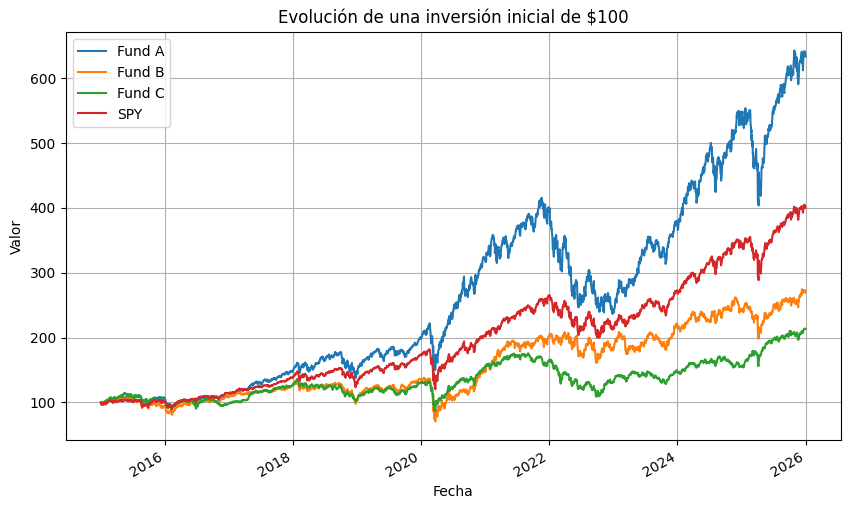

In [53]:
cum = 100 * (1 + df).cumprod()

cum.plot(figsize=(10, 6))
plt.title("Evolución de una inversión inicial de $100")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.grid(True)
plt.show()

In [61]:


def estimate_betas(sample,stock_list):
  results = []

  for stock in df.columns:
     regression = sm.OLS(sample[stock],sm.add_constant(sample["SPY"])).fit()
     results.append([stock,regression.params["const"],regression.pvalues["const"],
                     regression.params["SPY"],regression.pvalues["SPY"],regression.rsquared])
  return pd.DataFrame(results,columns = ["Stock","Alpha", "Alpha p-value","Beta","Beta p-value","R-squared"]).set_index("Stock")


full_betas = estimate_betas(df,df.columns)
display(full_betas.sort_values("Beta",ascending = False).round(6))

,Alpha,Alpha p-value,Beta,Beta p-value,R-squared
Stock,,,,,
Fund A,0.000098,0.360514,1.197705,0.0,0.850227
Fund B,-0.000150,0.230633,1.066965,0.0,0.768710
SPY,-0.000000,0.150114,1.000000,0.0,1.000000
Fund C,-0.000086,0.530440,0.748355,0.0,0.574611


## 2. Understanding Market Risk: CAPM Analysis

**Your client asks:**

> I understand that all three funds invest in equities, but I would like to know whether they take the same level of market risk.
>
> Which fund is most sensitive to movements in the S&P 500? If the market rises or falls by 1%, how much would you expect each fund to move?
>
> I would also like to understand how much of each fund's return variability is explained by market movements. Does a higher market beta necessarily mean that the market explains a greater proportion of the fund's fluctuations?
>
> Finally, have any of the funds generated returns beyond those explained by their exposure to the market? Is there statistically significant evidence of such performance?

**Prepare an analysis using the CAPM and present the estimated coefficients, their statistical significance, and the explanatory power of the model. Conclude with an assessment of the three funds from a financial advisor's perspective.**

In [88]:
def estimate_betas(sample,stock_list):
  results = []

  for stock in df.columns:
     regression = sm.OLS(sample[stock],sm.add_constant(sample["SPY"])).fit()
     results.append([stock,regression.params["const"],regression.pvalues["const"],
                     regression.params["SPY"],regression.pvalues["SPY"],regression.rsquared])
  return pd.DataFrame(results,columns = ["Stock","Alpha", "Alpha p-value","Beta","Beta p-value","R-squared"]).set_index("Stock")


full_betas = estimate_betas(df,df.columns)
display(full_betas.sort_values("Beta",ascending = False).round(6))

,Alpha,Alpha p-value,Beta,Beta p-value,R-squared
Stock,,,,,
Fund A,0.000098,0.360514,1.197705,0.0,0.850227
Fund B,-0.000150,0.230633,1.066965,0.0,0.768710
SPY,-0.000000,0.150114,1.000000,0.0,1.000000
Fund C,-0.000086,0.530440,0.748355,0.0,0.574611


## 3. What Investment Styles Are We Actually Buying?

**Your client asks:**

> I understand that Funds A, B and C have different returns and market sensitivities. However, I would like to know more about the types of companies their managers invest in.
>
> Do these funds mainly behave like portfolios of large or small companies? Do they follow a value or growth investment style? Can you identify these characteristics without knowing their actual holdings?
>
> I would also like to know whether the differences in their historical performance can be explained by these investment styles. Does considering additional risk factors change your assessment of the managers' performance compared with the CAPM?
>
> Finally, how reliable are these findings? Which conclusions are supported by statistically significant evidence?

**Prepare a comparative analysis of the three funds using the Fama-French three-factor model. Explain their investment styles, evaluate their risk-adjusted performance, and assess whether the additional factors improve the explanation of fund returns.**

In [67]:
print('US factors:', ff_us.columns.tolist())
print('European factors:', ff_europe.columns.tolist())
print('US industry portfolios:', industries_us.columns.tolist())

US factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
European factors: ['Mkt-RF', 'SMB', 'HML', 'RF']
US industry portfolios: ['Cnsmr', 'Manuf', 'HiTec', 'Hlth', 'Other']


In [86]:
# 1. Convertimos los retornos diarios a mensuales compuestos
df_monthly = (1 + df).resample('ME').prod() - 1

# 2. Ajustamos el formato del índice para que coincida con ff_us (YYYY-MM)
df_monthly.index = df_monthly.index.to_period('M')

# 3. Combinamos los retornos mensuales de nuestros fondos con los factores de EE.UU.
# Nota: Restamos la tasa libre de riesgo (RF) a los retornos para obtener excesos de retorno
ff_analysis = df_monthly.join(ff_us, how='inner')

for col in ['Fund A', 'Fund B', 'Fund C', 'SPY']:
    ff_analysis[f'{col}-RF'] = ff_analysis[col] - ff_analysis['RF']

# 4. Estimamos el modelo de Fama-French de 3 Factores para cada fondo
results_ff = []
for fund in ['Fund A', 'Fund B', 'Fund C']:
    X = sm.add_constant(ff_analysis[['Mkt-RF', 'SMB', 'HML']])
    y = ff_analysis[f'{fund}-RF']
    model = sm.OLS(y, X).fit()
    results_ff.append([
        fund,
        model.params['const'],      # Alpha mensual
        model.pvalues['const'],     # p-valor del Alpha
        model.params['Mkt-RF'],     # Beta de Mercado
        model.params['SMB'],        # Exposición a Tamaño (Small Minus Big)
        model.params['HML'],        # Exposición a Estilo (High Minus Low / Value)
        model.rsquared              # R-cuadrado del modelo
    ])

df_ff_results = pd.DataFrame(
    results_ff,
    columns=['Fund', 'Alpha (Monthly)', 'Alpha p-value', 'Beta Market', 'Beta SMB (Size)', 'Beta HML (Value)', 'R-squared']
).set_index('Fund')

display(df_ff_results.round(4))

,Alpha (Monthly),Alpha p-value,Beta Market,Beta SMB (Size),Beta HML (Value),R-squared
Fund,,,,,,
Fund A,0.0024,0.0856,1.1446,0.0773,-0.4507,0.9281
Fund B,-0.0022,0.1101,1.1255,0.3293,0.5109,0.9362
Fund C,-0.0037,0.1231,0.8859,-0.1737,0.0884,0.6837


## 4. Could We Be Looking at Funds from Different Regions?

**Your client asks:**

> So far, we have evaluated all three funds using US market factors. However, I do not know whether their managers invest primarily in US or European equities.
>
> Can you determine which geographical market best explains each fund's historical returns?
>
> Does using European rather than US factors change your assessment of their market sensitivity, investment styles, or performance?
>
> How confident are you in identifying the geographical exposure of each fund from its returns alone?

**Prepare a comparative analysis using US and European Fama-French factors. Identify the most appropriate geographical reference for each fund and explain how your conclusions change depending on the factors used.**

## 5. What Industries Drive the Funds' Performance?

**Your client asks:**

> We have identified important differences in the investment styles of Funds A and B. However, I would also like to understand the types of businesses driving their returns.
>
> Are these funds primarily exposed to technology, consumer businesses, manufacturing, healthcare, or other industries?
>
> Which industries appear to be most important for each fund? Are these exposures consistent with the investment styles you identified earlier?
>
> How much of each fund's historical behavior can be explained by industry returns?
>
> Finally, can you estimate the exact percentage invested in each industry from this analysis, or would you need additional information?

**Prepare a comparative industry exposure analysis for Funds A and B. Explain the economic interpretation of your results, evaluate their statistical significance, and discuss the limitations of identifying portfolio holdings from historical returns.**

## 6. Do These Risks Change Over Time and Across Market Conditions?

**Your client asks:**

> You have estimated the funds' market sensitivities using historical data. However, I am concerned that these risks may change over time.
>
> Have the funds' market betas remained stable over the past decade? Please show me how they have evolved using five-year rolling windows.
>
> More importantly, I am particularly concerned about market downturns. Do these funds react differently when the US stock market rises and when it falls?
>
> Which fund appears to offer better protection during negative market conditions? Can I rely on these historical relationships when making future investment decisions?

**Prepare an analysis of the funds' changing market sensitivities, comparing their behavior during positive and negative market conditions. Explain the implications for an investor concerned about downside risk and discuss the reliability of your findings.**

## 7. Your investment recommendation

**Your client asks:**

> I am comparing the three funds for two investors. The first has a long horizon and is prepared to accept substantial short-term losses in pursuit of growth. The second is particularly concerned about large losses and diversification relative to the S&P 500.

> Which fund, if any, would you recommend to each investor? What evidence supports your advice, what risks remain, and what additional information would you request before investing?

Prepare a **300–400-word advisory memo**. Base your recommendation on your analysis rather than on past returns alone. State clearly what cannot be inferred from return data.

---

**Data sources:** Kenneth R. French Data Library (US three factors, European three factors and US five-industry portfolios); anonymized fund return series supplied for this assignment.

**Selected literature:** Sharpe (1964), *The Journal of Finance*, 19(3), 425–442; Fama and French (1993), *Journal of Financial Economics*, 33(1), 3–56.